In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Aim of this project

The aim of this project is to approximate the function
$$ g(x) = \sin(x)+0.2\sin(5x) $$
over the interval $x\in[-\pi,\pi]$ using neural networks. To do this we will start by generating a list of 40 evenly space training inputs. Namely, 40 tuples of $(x,g(x))$.

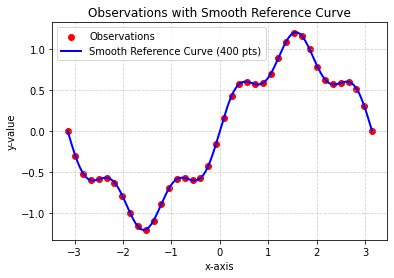

In [4]:
# Generating the set of data points

xval = np.array([])

for i in range(40):
    xval = np.append(xval, -np.pi + 2*np.pi*i/39)

# Arranges into the desired shape of (1,40)
x = np.array([xval])

# Generating the corresponding set of y-value points. Together the x and y arrays are our 
# observations for the neural network
yval = np.array([])

for i in range(x[0].size):
    yval = np.append(yval, np.sin(x[0][i])+0.2*np.sin(5*x[0][i]))

# Arranging into a (1,40) array

y = np.array([yval])

# Plotting the observations using 400 smooth inputs

x_smooth = np.linspace(-np.pi, np.pi, 400)
y_smooth = np.sin(x_smooth)+0.2*np.sin(5*x_smooth)

# Plots the observations individually as red dots
plt.scatter(x, y, color='red', marker='o', label='Observations')

# Plot the smooth reference curve using the 400 inputs
plt.plot(x_smooth, y_smooth, color='blue', linestyle='-', linewidth=2, label='Smooth Reference Curve (400 pts)')

# Chart styling
plt.title('Observations with Smooth Reference Curve')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

In [5]:
## Setting up the fundamental machinery for the neural network

# Sets the random generator’s starting state to 0
torch.manual_seed(0)

# Randomly generate weight tensors
W1 = (0.1 * torch.randn(16, 1, dtype=torch.float64)).requires_grad_()
W2 = (0.1 * torch.randn(16, 16, dtype=torch.float64)).requires_grad_()
W3 = (0.1 * torch.randn(1, 16, dtype=torch.float64)).requires_grad_()

# Initialising biases to 0

b1 = torch.zeros(16, 1, dtype=torch.float64, requires_grad=True)
b2 = torch.zeros(16, 1, dtype=torch.float64, requires_grad=True)
b3 = torch.zeros(1, 1, dtype=torch.float64, requires_grad=True)

# Converting our observation data to PyTorch tensors

X = torch.tensor(x, dtype=torch.float64, requires_grad=False)
Y = torch.tensor(y, dtype=torch.float64, requires_grad=False)

In [6]:
def forward_pass(W1, W2, W3, b1, b2, b3, X):
    H1 = torch.tanh(W1@X + b1)
    H2 = torch.tanh(W2@H1 + b2)
    Yhat = W3@H2 + b3
    return Yhat

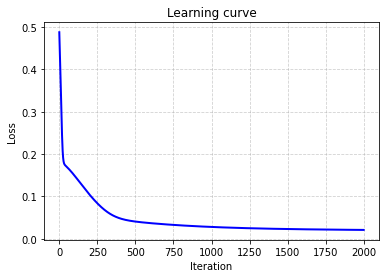

In [7]:
# Training

eta = 0.05
lossvalues =[]

for i in range(2000):
    # Clearing gradient values
    W1.grad = None
    W2.grad = None
    W3.grad = None
    b1.grad = None
    b2.grad = None
    b3.grad = None
    
    # Running forward pass and appending loss value to the list of loss values
    R = forward_pass(W1, W2, W3, b1, b2, b3, X) - Y
    L = (R @ R.T) / R.shape[1]
    lossvalues.append(L.item())
    
    # Running the backwards pass
    L.backward()
    
    # Updates the four parameters
    with torch.no_grad():
        W1 -= eta*W1.grad
        W2 -= eta*W2.grad
        W3 -= eta*W3.grad
        b1 -= eta*b1.grad
        b2 -= eta*b2.grad
        b3 -= eta*b3.grad

# Plotting the learning curve
plt.plot(lossvalues, color='blue', linestyle='-', linewidth=2)

# Chart styling
plt.title('Learning curve')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

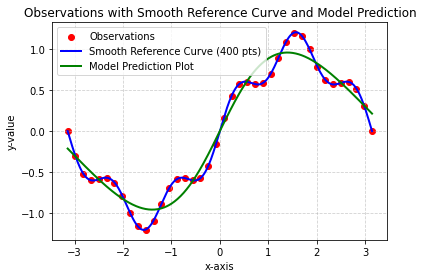

In [8]:
# Converting x_smooth in tensor
Xsmooth = torch.tensor(x_smooth.reshape(1,400), dtype=torch.float64, requires_grad=False)

# Calculating predicted values without changing the weights or training. Tests what the current 
# weights are modelling
with torch.no_grad():
    Ysmooth = forward_pass(W1, W2, W3, b1, b2, b3, Xsmooth)

# Plots the observations individually as red dots
plt.scatter(x, y, color='red', marker='o', label='Observations')

# Plot the smooth reference curve using the 400 inputs
plt.plot(x_smooth, y_smooth, color='blue', linestyle='-', linewidth=2, label='Smooth Reference Curve (400 pts)')

# Plots the models current prediction
plt.plot(Xsmooth[0], Ysmooth[0], color ='green', linestyle = '-', linewidth=2, label='Model Prediction Plot')

# Chart styling
plt.title('Observations with Smooth Reference Curve and Model Prediction')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

# Plotting residuals

It's not hard to see from the above plot that it looks like the model is approximating the function $sin(x)$. As such, we are going to plot residuals, an actual residual and a hypothesised residual to test whether this is true. Namely, the residual, is simply 
$$ r(x) = \hat{y}(x)-y(x) $$
where $g(x)=\sin(x) + 0.2\sin(5x)$ from above. Now from our assumption that the function is approximating $sin(x)$, we can also plot a hypothesised residual. Namely since we are assuming that currently $\hat{y}(x)=\sin(x)$, we can plot:
$$ r'(x) = \sin(x)-g(x) = \sin(x)-[\sin(x)+0.2\sin(5x)] = -0.2\sin(5x) $$
Or in other words, we are going to plot $-0.2\sin(5x)$ with our data points. Comparing these two residuals graphically will give us valuable information about our neural network.

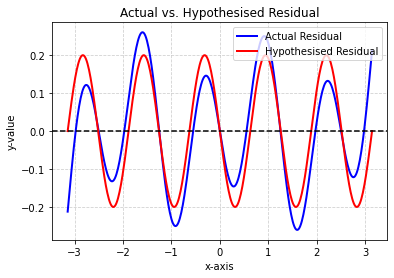

In [9]:
# Defining the actual residual
r1 = Ysmooth[0]-y_smooth

# Defining the hypothesised residual
r2 = -0.2 * np.sin(5*x_smooth)

# Plotting the two residual curves
plt.plot(x_smooth, r1, color='blue', linestyle='-', linewidth=2, label='Actual Residual')

# Plots the models current prediction
plt.plot(x_smooth, r2, color ='red', linestyle = '-', linewidth=2, label='Hypothesised Residual')

# Plotting a horizontal line at y=0

plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5)

# Chart styling
plt.title('Actual vs. Hypothesised Residual')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

Quite clearly, our hypothesis is not entirely accurate. To test this we are going to plot the difference between our expected and actual residual. This will tell us the difference and therefore deviation at each point of our expectation and what the neural net is producing. Or in other words, the deviation from a sine wave. This will give some very valuable information about our network. 

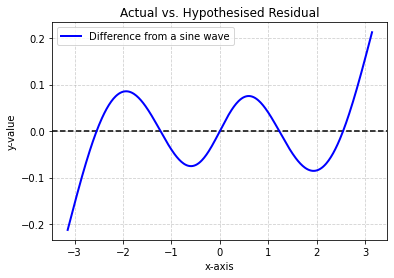

In [10]:
# Plotting a horizontal line at y=0

plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5)

# Plotting the difference between hypothesised and expected residual

diff = r1 - r2

plt.plot(x_smooth, diff, color='blue', linestyle='-', linewidth=2, label='Difference from a sine wave')


# Chart styling
plt.title('Actual vs. Hypothesised Residual')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

To try and fix the issue we will try running the model for a further 8000 iterations. Namely, we will train it for longer to see if this produces a better result.

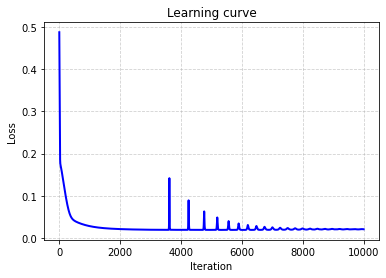

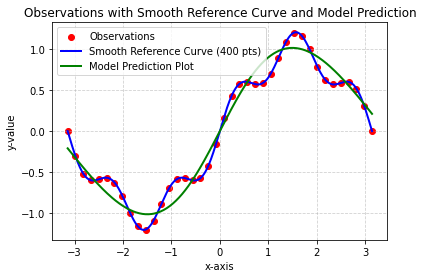

In [11]:
for i in range(8000):
    # Clearing gradient values
    W1.grad = None
    W2.grad = None
    W3.grad = None
    b1.grad = None
    b2.grad = None
    b3.grad = None
    
    # Running forward pass and appending loss value to the list of loss values
    R = forward_pass(W1, W2, W3, b1, b2, b3, X) - Y
    L = (R @ R.T) / R.shape[1]
    lossvalues.append(L.item())
    
    # Running the backwards pass
    L.backward()
    
    # Updates the four parameters
    with torch.no_grad():
        W1 -= eta*W1.grad
        W2 -= eta*W2.grad
        W3 -= eta*W3.grad
        b1 -= eta*b1.grad
        b2 -= eta*b2.grad
        b3 -= eta*b3.grad

# Plotting the learning curve
plt.plot(lossvalues, color='blue', linestyle='-', linewidth=2)

# Chart styling
plt.title('Learning curve')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

# Converting x_smooth in tensor
Xsmooth = torch.tensor(x_smooth.reshape(1,400), dtype=torch.float64, requires_grad=False)

# Calculating predicted values without changing the weights or training. Tests what the current 
# weights are modelling
with torch.no_grad():
    Ysmooth = forward_pass(W1, W2, W3, b1, b2, b3, Xsmooth)

# Plots the observations individually as red dots
plt.scatter(x, y, color='red', marker='o', label='Observations')

# Plot the smooth reference curve using the 400 inputs
plt.plot(x_smooth, y_smooth, color='blue', linestyle='-', linewidth=2, label='Smooth Reference Curve (400 pts)')

# Plots the models current prediction
plt.plot(Xsmooth[0], Ysmooth[0], color ='green', linestyle = '-', linewidth=2, label='Model Prediction Plot')

# Chart styling
plt.title('Observations with Smooth Reference Curve and Model Prediction')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

Evidently, training the model longer has not helped and moreover, it is clear that there are intermittent spikes that are associated with overshooting. As described by ChatGPT, 'a fixed learning rate can work initially, then become too large as the parameters move into regions where the loss has greater curvature. This doesn’t establish that the network lacks capacity.' To try and diagnose and adapt, we will try to change the learning rate, to see if this helps. Before we begin, we will do some brief calculations to aid in the further research.

Final training MSE: 0.020425416979681137
Dense-grid MSE: 0.019523648168377403


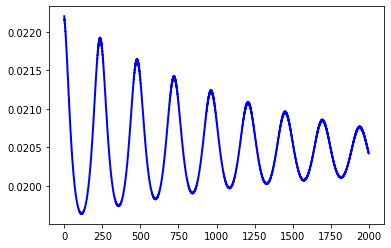

In [12]:
# Final training MSE
with torch.no_grad():
    R = forward_pass(W1, W2, W3, b1, b2, b3, X) - Y
    L = (R @ R.T) / R.shape[1]
    
print("Final training MSE:", L.item())

# 400-point grid MSE
grid_predictions = Ysmooth[0]
grid_residual = grid_predictions - y_smooth
grid_mse = (grid_residual**2).mean()

print("Dense-grid MSE:", grid_mse.item())


# Plot of last 2000-recorded losses
plt.plot(lossvalues[-2000:], color='blue', linestyle='-', linewidth=2)

It is important to note that the difference in final training and dense-grid MSE illustrates that the main difficulty is fitting the function rather than a large loss of accuracy between training points. To continue, we are going to adjust the learning rate and set it to $\eta=0.005$, 10 times smaller. We will continue from where the weights are for 2,000 additional updates.

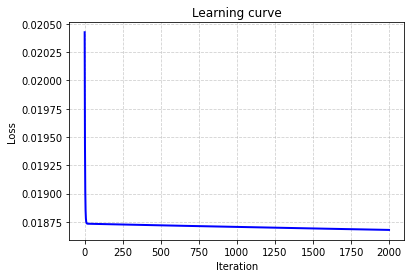

Final training MSE: 0.018679306646647152


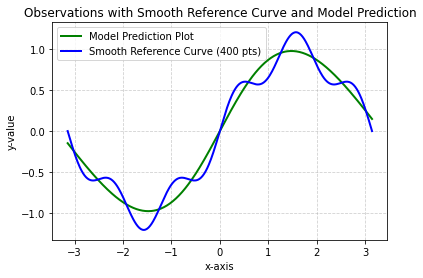

In [13]:
# Training with the new learning rate

etanew = 0.005
lossvaluesnew =[]

for i in range(2000):
    # Clearing gradient values
    W1.grad = None
    W2.grad = None
    W3.grad = None
    b1.grad = None
    b2.grad = None
    b3.grad = None
    
    # Running forward pass and appending loss value to the list of loss values
    R = forward_pass(W1, W2, W3, b1, b2, b3, X) - Y
    L = (R @ R.T) / R.shape[1]
    lossvaluesnew.append(L.item())
    
    # Running the backwards pass
    L.backward()
    
    # Updates the four parameters
    with torch.no_grad():
        W1 -= etanew*W1.grad
        W2 -= etanew*W2.grad
        W3 -= etanew*W3.grad
        b1 -= etanew*b1.grad
        b2 -= etanew*b2.grad
        b3 -= etanew*b3.grad

# Plotting the learning curve
plt.plot(lossvaluesnew, color='blue', linestyle='-', linewidth=2)

# Chart styling
plt.title('Learning curve')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

# Computing updated final training loss
with torch.no_grad():
    R = forward_pass(W1, W2, W3, b1, b2, b3, X) - Y
    L = (R @ R.T) / R.shape[1]
    
print("Final training MSE:", L.item())

# Calculating predicted values without changing the weights or training. Tests what the current 
# weights are modelling
with torch.no_grad():
    Ysmooth = forward_pass(W1, W2, W3, b1, b2, b3, Xsmooth)
    
# Plots the models current prediction
plt.plot(Xsmooth[0], Ysmooth[0], color ='green', linestyle = '-', linewidth=2, label='Model Prediction Plot')
# Plot the smooth reference curve using the 400 inputs
plt.plot(x_smooth, y_smooth, color='blue', linestyle='-', linewidth=2, label='Smooth Reference Curve (400 pts)')
# Chart styling
plt.title('Observations with Smooth Reference Curve and Model Prediction')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

In [14]:
grid_residual = Ysmooth[0].numpy() - y_smooth
print("Dense-grid MSE:", (grid_residual**2).mean())
print("Starting training MSE:", lossvaluesnew[0])

Dense-grid MSE: 0.01835838494806105
Starting training MSE: 0.020425416979681137


With a few extra tests tweaking the number of iterations as well as the learning rate, it seems that the network is still not improving. It seems to be stagnating with a loss around $0.01868$. I hypothesise that the issue is more related to the data set, namely we only have 40 observation points. I hypothesise that increasing the size of the data set, thereby giving the network more training points will drastically improve the outcome. In order to do so, I am going to rewrite the training model as a function as below.

In [15]:
def train_model(Xtrain, Ytrain, seed=0, eta=0.005, steps=10000, width=16):
    
    torch.manual_seed(seed)

    # Randomly generate weight tensors
    W1 = (0.1 * torch.randn(width, 1, dtype=torch.float64)).requires_grad_()
    W2 = (0.1 * torch.randn(width, width, dtype=torch.float64)).requires_grad_()
    W3 = (0.1 * torch.randn(1, width, dtype=torch.float64)).requires_grad_()

    # Initialising biases to 0

    b1 = torch.zeros(width, 1, dtype=torch.float64, requires_grad=True)
    b2 = torch.zeros(width, 1, dtype=torch.float64, requires_grad=True)
    b3 = torch.zeros(1, 1, dtype=torch.float64, requires_grad=True)
    
    lossvalues =[]

    for i in range(steps):
        # Clearing gradient values
        W1.grad = None
        W2.grad = None
        W3.grad = None
        b1.grad = None
        b2.grad = None
        b3.grad = None

        # Running forward pass and appending loss value to the list of loss values
        R = forward_pass(W1, W2, W3, b1, b2, b3, Xtrain) - Ytrain
        L = (R @ R.T) / R.shape[1]
        lossvalues.append(L.item())

        # Running the backwards pass
        L.backward()

        # Updates the four parameters
        with torch.no_grad():
            W1 -= eta*W1.grad
            W2 -= eta*W2.grad
            W3 -= eta*W3.grad
            b1 -= eta*b1.grad
            b2 -= eta*b2.grad
            b3 -= eta*b3.grad
            
    return (W1, W2, W3, b1, b2, b3), lossvalues

In [16]:
# Generating 40 and 160-point datasets over the interval

x40 = np.linspace(-np.pi,np.pi,40).reshape(1,40)
y40 = np.sin(x40)+0.2*np.sin(5*x40).reshape(1,40)

x160 = np.linspace(-np.pi,np.pi,160).reshape(1,160)
y160 = np.sin(x160)+0.2*np.sin(5*x160).reshape(1,160)

X40 = torch.tensor(x40, dtype=torch.float64, requires_grad=False)
Y40 = torch.tensor(y40, dtype=torch.float64, requires_grad=False)

X160 = torch.tensor(x160, dtype=torch.float64, requires_grad=False)
Y160 = torch.tensor(y160, dtype=torch.float64, requires_grad=False)

40-point training MSE: 0.02771661717305815
40-point dense-grid MSE: 0.025341694139398116
160-point training MSE: 0.027450645495601618
160-point dense-grid MSE: 0.026987939585992347


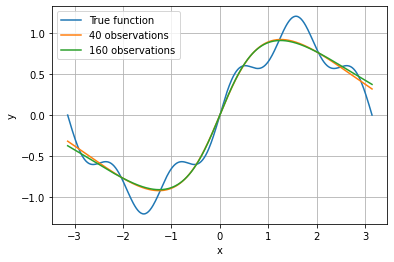

In [17]:
# Running the training model on the 40 and 160-point datasets and storing their values in a convenient form

params40, losses40 = train_model(X40, Y40)
params160, losses160 = train_model(X160, Y160)

# Converts our smooth function into a PyTorch tensor 
Xeval = torch.tensor(x_smooth.reshape(1, -1), dtype=torch.float64)
Yeval = torch.tensor(y_smooth.reshape(1, -1), dtype=torch.float64)

# Runs both the predicted and actual models and calculates the training MSE and grid MSE. NOTE: The * in
# *params40 unpacks the 6-tuple of parameter tensors into individual components that can be parsed by
# forward_pass()
with torch.no_grad():
    train_pred40 = forward_pass(*params40, X40)
    grid_pred40 = forward_pass(*params40, Xeval)

    train_mse40 = ((train_pred40 - Y40)**2).mean().item()
    grid_mse40 = ((grid_pred40 - Yeval)**2).mean().item()

print("40-point training MSE:", train_mse40)
print("40-point dense-grid MSE:", grid_mse40)

# Same as above for the 160-point set

with torch.no_grad():
    train_pred160 = forward_pass(*params160, X160)
    grid_pred160 = forward_pass(*params160, Xeval)

    train_mse160 = ((train_pred160 - Y160)**2).mean().item()
    grid_mse160 = ((grid_pred160 - Yeval)**2).mean().item()

print("160-point training MSE:", train_mse160)
print("160-point dense-grid MSE:", grid_mse160)

plt.plot(x_smooth, y_smooth, label="True function")
plt.plot(x_smooth, grid_pred40[0].numpy(), label="40 observations")
plt.plot(x_smooth, grid_pred160[0].numpy(), label="160 observations")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

Clearly one can see that increasing the data set hasn't really improved the result. As such we need to look at the loss functions to determine if they can give us any valuable information. Importantly, we can look for the following things:
- Repeated increases or oscillations: evidence that the step size may be too large.
- Smooth, continuing decreases: lowering the learning rate might merely slow progress.
- An almost flat curve: requires further diagnosis; it doesn’t identify the cause by itself.

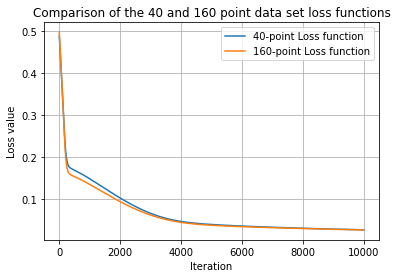

In [18]:
# Plot of the loss functions for all iterations

plt.plot(losses40, label="40-point Loss function")
plt.plot(losses160, label="160-point Loss function")

plt.title('Comparison of the 40 and 160 point data set loss functions')
plt.xlabel("Iteration")
plt.ylabel("Loss value")
plt.legend()
plt.grid(True)
plt.show()

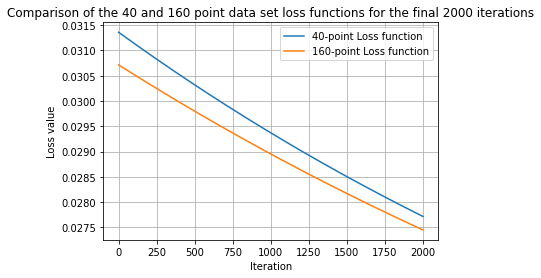

In [19]:
# Plot of the loss functions for the final 2000 iterations

plt.plot(losses40[-2000:], label="40-point Loss function")
plt.plot(losses160[-2000:], label="160-point Loss function")

plt.title('Comparison of the 40 and 160 point data set loss functions for the final 2000 iterations')
plt.xlabel("Iteration")
plt.ylabel("Loss value")
plt.legend()
plt.grid(True)
plt.show()

## What these graphs tell us

From these graphs it's clear the loss is still decreasing and the model is indeed training. However, it is notable that the loss decreases beging to rapidly slow. In other words, the step size becomes too small. What this means is that we need to change our learning rate. We need to make it larger so that the model step sizes are bigger and therefore losses decrease quicker. We want to be careful not to overdo it and accidentally go too far to the point the model becomes oscillatory, so we will plot these as we go. 

40-point training MSE for 0.01 learning rate: 0.020793622107084818
40-point dense-grid MSE for 0.01 learning rate: 0.019830654777132854
160-point training MSE for 0.01 learning rate: 0.0207071590643649
160-point dense-grid MSE for 0.01 learning rate: 0.02050569912293473


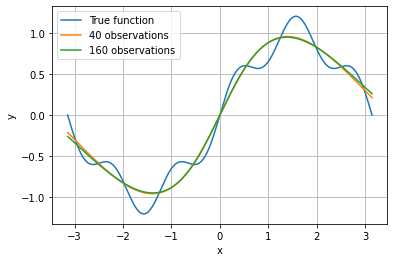

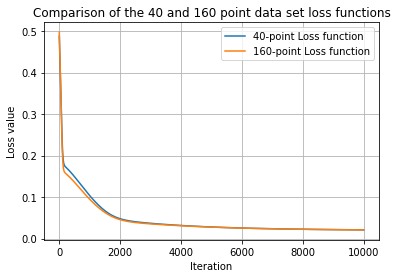

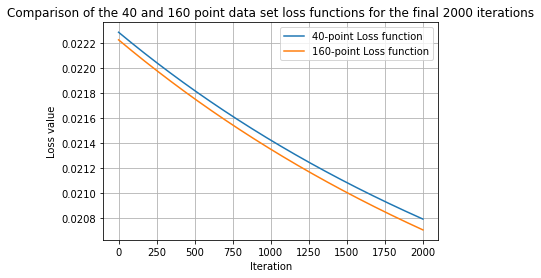

In [20]:
# Reruns the training model on the 40 and 160-point datasets with a learning rate of 0.01

params40n, losses40n = train_model(X40, Y40, eta=0.01)
params160n, losses160n = train_model(X160, Y160, eta=0.01)

# Converts our smooth function into a PyTorch tensor 
Xeval = torch.tensor(x_smooth.reshape(1, -1), dtype=torch.float64)
Yeval = torch.tensor(y_smooth.reshape(1, -1), dtype=torch.float64)

# Runs both the predicted and actual models and calculates the training MSE and grid MSE. NOTE: The * in
# *params40 unpacks the 6-tuple of parameter tensors into individual components that can be parsed by
# forward_pass()
with torch.no_grad():
    train_pred40n = forward_pass(*params40n, X40)
    grid_pred40n = forward_pass(*params40n, Xeval)

    train_mse40n = ((train_pred40n - Y40)**2).mean().item()
    grid_mse40n = ((grid_pred40n - Yeval)**2).mean().item()

print("40-point training MSE for 0.01 learning rate:", train_mse40n)
print("40-point dense-grid MSE for 0.01 learning rate:", grid_mse40n)

# Same as above for the 160-point set

with torch.no_grad():
    train_pred160n = forward_pass(*params160n, X160)
    grid_pred160n = forward_pass(*params160n, Xeval)

    train_mse160n = ((train_pred160n - Y160)**2).mean().item()
    grid_mse160n = ((grid_pred160n - Yeval)**2).mean().item()

print("160-point training MSE for 0.01 learning rate:", train_mse160n)
print("160-point dense-grid MSE for 0.01 learning rate:", grid_mse160n)


# Seperating into 2 plots of observation and learning curve

plt.figure(1)
plt.plot(x_smooth, y_smooth, label="True function")
plt.plot(x_smooth, grid_pred40n[0].numpy(), label="40 observations")
plt.plot(x_smooth, grid_pred160n[0].numpy(), label="160 observations")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(2)
plt.plot(losses40n, label="40-point Loss function")
plt.plot(losses160n, label="160-point Loss function")

plt.title('Comparison of the 40 and 160 point data set loss functions')
plt.xlabel("Iteration")
plt.ylabel("Loss value")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(3)
plt.plot(losses40n[-2000:], label="40-point Loss function")
plt.plot(losses160n[-2000:], label="160-point Loss function")

plt.title('Comparison of the 40 and 160 point data set loss functions for the final 2000 iterations')
plt.xlabel("Iteration")
plt.ylabel("Loss value")
plt.legend()
plt.grid(True)
plt.show()

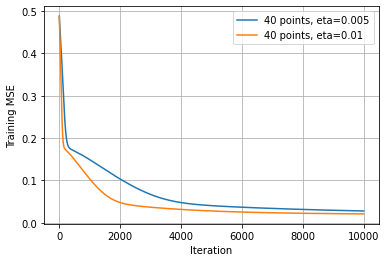

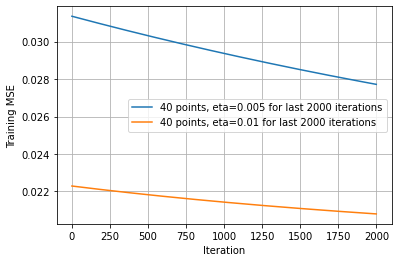

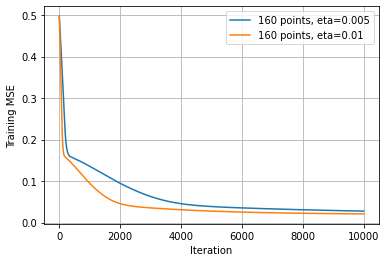

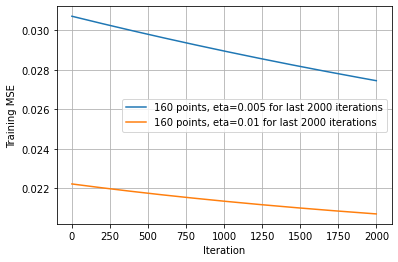

In [21]:
# Directly comparing the learning curves of the varying learning rates

plt.figure(1)
plt.plot(losses40, label="40 points, eta=0.005")
plt.plot(losses40n, label="40 points, eta=0.01")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(2)
plt.plot(losses40[-2000:], label="40 points, eta=0.005 for last 2000 iterations")
plt.plot(losses40n[-2000:], label="40 points, eta=0.01 for last 2000 iterations")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(3)
plt.plot(losses160, label="160 points, eta=0.005")
plt.plot(losses160n, label="160 points, eta=0.01")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(4)
plt.plot(losses160[-2000:], label="160 points, eta=0.005 for last 2000 iterations")
plt.plot(losses160n[-2000:], label="160 points, eta=0.01 for last 2000 iterations")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True)
plt.show()


Quite clearly this hasn't really helped. As such we need to look for something else. When we designed the network architecture we designed it with 2 hidden layers and a $1\rightarrow 16\rightarrow 16\rightarrow 1$ layout. We will now change this architecture so that it can be of the form $1\rightarrow n\rightarrow n\rightarrow 1$ to test whether changing the number of neurons in the hidden layers helps. To do so we will simply edit the code for train_model() so that it has a width argument. For example we will rewrite the input as:
train_model(Xtrain, Ytrain, seed=0, eta=0.005, steps=10000, width=16) 
and adapt the initialisation of our parameter tensors as: 
W1 = (0.1 * torch.randn(width, 1, dtype=torch.float64)).requires_grad_()

40-point training MSE for 32 width network: 0.02062569474268409
40-point dense-grid MSE for 32 width network: 0.01969326781960827


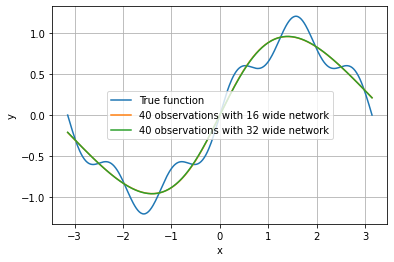

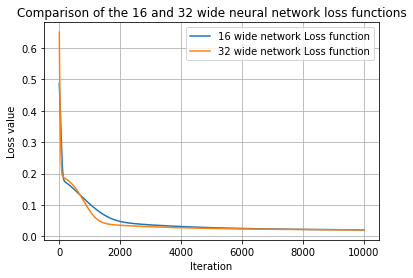

In [22]:
# Training runs for the 32 width network

params32, losses32 = train_model(X40, Y40, eta=0.01, width=32)

with torch.no_grad():
    train_pred32 = forward_pass(*params32, X40)
    grid_pred32 = forward_pass(*params32, Xeval)

    train_mse32 = ((train_pred32 - Y40)**2).mean().item()
    grid_mse32 = ((grid_pred32 - Yeval)**2).mean().item()

print("40-point training MSE for 32 width network:", train_mse32)
print("40-point dense-grid MSE for 32 width network:", grid_mse32)

# Plots comparing the 16 and 32 width networks for 40 point datasets

plt.figure(1)
plt.plot(x_smooth, y_smooth, label="True function")
plt.plot(x_smooth, grid_pred40n[0].numpy(), label="40 observations with 16 wide network")
plt.plot(x_smooth, grid_pred32[0].numpy(), label="40 observations with 32 wide network")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(2)
plt.plot(losses40n, label="16 wide network Loss function")
plt.plot(losses32, label="32 wide network Loss function")

plt.title('Comparison of the 16 and 32 wide neural network loss functions')
plt.xlabel("Iteration")
plt.ylabel("Loss value")
plt.legend()
plt.grid(True)
plt.show()

# Issues previal

Clearly the issues are indeed prevailing. We are not making any progress in terms of reducing the loss and thereby not accurately fitting our function. The training is slowing and the network is not making any progress. One idea is that we are not accurately updating our parameters each iteration. Namely, at the moment we are using stochastic gradient descent (SDG) whereby after backpropagation and calculating the gradient descent vectors, we update the parameters according to the rule:
$$ \theta_k = \theta_{k-1}-\eta_k\nabla_\mathcal{L}(\theta_k) $$
With a constant learning rate, $\eta_k=\eta, \forall k$, we hypothesise that the parameter updates are too small. As such we will change our paramater update method and use the method known as Adam. 

Standing for Adaptive Moment Estimation is an optimisation method that trains neural networks by combining momentum and adaptive scaling to train the neural network more effectively. Specifically, it uses a gradient history enabling past gradient directions to influence the next parameter update and ensure that we take into consideration our entire training algorithm, not just the current gradient direction. Adaptive scaling furthers this by ensuring that the next paramater update is scaled appropriately with consideration from past updates, not just being influenced solely by our learning rate. In our case, this is particularly important, as it is clear that our learning curve quickly decreases then rapidly slows. If we take into consideration the entire gradient history and ultimately update our paramaters with an adapated scale, not just a constant magnitude determined by the learning rate, we likely will be able to continue this rapid loss decrease. Ultimately, this means our network will likely be able to consider the smaller oscillations in the desired function and therefore do a better job of fitting this, as opposed to our current network which misses these oscillations. 

In [62]:
# Implementing Adam. Rewriting the train_model() function to optimize with Adam

def train_model_adam(Xtrain, Ytrain, seed=0, eta=0.001, steps=10000, width=16):
    
    torch.manual_seed(seed)

    # Randomly generate weight tensors
    W1 = (0.1 * torch.randn(width, Xtrain.shape[0], dtype=torch.float64)).requires_grad_()
    W2 = (0.1 * torch.randn(width, width, dtype=torch.float64)).requires_grad_()
    W3 = (0.1 * torch.randn(1, width, dtype=torch.float64)).requires_grad_()

    # Initialising biases to 0

    b1 = torch.zeros(width, 1, dtype=torch.float64, requires_grad=True)
    b2 = torch.zeros(width, 1, dtype=torch.float64, requires_grad=True)
    b3 = torch.zeros(1, 1, dtype=torch.float64, requires_grad=True)
    
    lossvalues =[]
    
    # Initialising the paramaters and optimiser
    paramaters = [W1, W2, W3, b1, b2, b3]
    optimiser = torch.optim.Adam(paramaters, lr=eta)
    
    for i in range(steps):
        
        # Clearing gradient values
        optimiser.zero_grad(set_to_none=True)

        # Running forward pass and appending loss value to the list of loss values
        R = forward_pass(*paramaters, Xtrain) - Ytrain
        L = (R @ R.T) / R.shape[1]
        lossvalues.append(L.item())

        # Running the backwards pass
        L.backward()

        # Updates all parameters
        optimiser.step()
            
    return (W1, W2, W3, b1, b2, b3), lossvalues

40-point training MSE for Adam optimiser: 1.6842409921530848e-05
40-point dense-grid MSE for Adam optimiser: 1.7602134164102996e-05


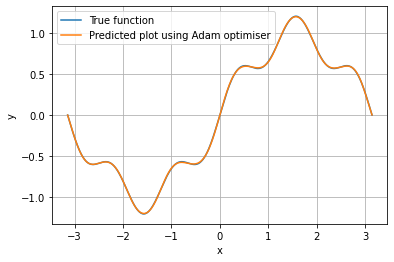

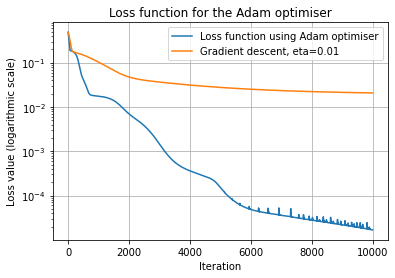

In [40]:
params_adam, losses_adam = train_model_adam(X40, Y40)

with torch.no_grad():
    train_pred_adam = forward_pass(*params_adam, X40)
    grid_pred_adam = forward_pass(*params_adam, Xeval)

    train_mse_adam = ((train_pred_adam - Y40)**2).mean().item()
    grid_mse_adam = ((grid_pred_adam - Yeval)**2).mean().item()

print("40-point training MSE for Adam optimiser:", train_mse_adam)
print("40-point dense-grid MSE for Adam optimiser:", grid_mse_adam)

# Plots of the Adam optimiser

plt.figure(1)
plt.plot(x_smooth, y_smooth, label="True function")
plt.plot(x_smooth, grid_pred_adam[0].numpy(), label="Predicted plot using Adam optimiser")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(2)
plt.plot(losses_adam, label="Loss function using Adam optimiser")
plt.plot(losses40n, label="Gradient descent, eta=0.01")
plt.yscale("log")
plt.title('Loss function for the Adam optimiser')
plt.xlabel("Iteration")
plt.ylabel("Loss value (logarithmic scale)")
plt.legend()
plt.grid(True)
plt.show()

## At last!

At last! We have finally overcome the stagnation that has limited our network. Evidently, the hypothesis about the paramater updates being limited by the constant magnitude proved correct. Adam effectively solved the issue through its use of adapative scaling and gradient history tracking. Now we will test the model by expanding the domain and number of data points to see whether it can accurately match the function on inputs outside it's training set.
We will increase the domain to $[-2\pi,2\pi]$ and the number of data points to $800$.

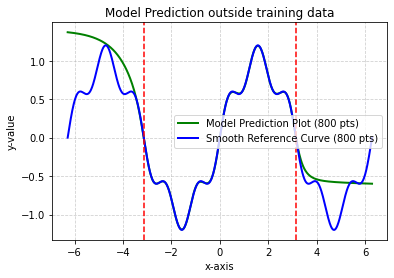

In [41]:
# Creating evenly spaced data points
xtest = np.linspace(-2*np.pi,2*np.pi,800).reshape(1,800)
Xtest = torch.tensor(xtest, dtype=torch.float64, requires_grad=False)

# Generating true values for the input points
ytrue = np.sin(xtest)+0.2*np.sin(5*xtest)

# Generates the predicted data points using the model
with torch.no_grad():
    Ypred = forward_pass(*params_adam, Xtest)

# Plots the models current prediction
plt.plot(Xtest[0].numpy(), Ypred[0].numpy(), color ='green', linestyle = '-', linewidth=2, label='Model Prediction Plot (800 pts)')
# Plot the smooth reference curve using the 800 inputs
plt.plot(xtest[0], ytrue[0], color='blue', linestyle='-', linewidth=2, label='Smooth Reference Curve (800 pts)')
# Chart styling
plt.title('Model Prediction outside training data')
plt.xlabel('x-axis')
plt.ylabel('y-value')
plt.axvline(x=-np.pi, color='red', linestyle='--')
plt.axvline(x=np.pi, color='red', linestyle='--')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

# Well, well, well

So we haven't really solved it have we. Turns out our model is a perfect fit for our dataset, but outside it fails. This largely stems from the fact that our activation function is $\tanh$ and in the limit that $x\rightarrow -\infty,\infty$, $\tanh\rightarrow -1,1$, respectively. This constancy is transmitted through the network leading to a assymptotic output, evident in the above graph. We can however look to exploit the periodicity of our function, which is clearly periodic in $2\pi$. I asked ChatGPT if it would be possible to adapt and change our activation function from $\tanh$ to $\sin$ or something periodic in $2\pi$. My idea was that this could then capture the peridocity that we need. However, as it states, "Periodic activations are a reasonable hypothesis, but they don’t automatically give the network the correct periodicity. The weights affect the frequencies, and combining neurons can complicate the resulting pattern." So we need another idea. We know that the function is very accurate in our observation domain. What if we can somehow exploit the fact the function is periodic by encoding it into our inputs and keeping the $\tanh$ network. Recalling that both $\sin(x+2\pi)=\sin(x)$ and $\cos(x+2\pi)=\cos(x)$, using a $\phi(x)$ layer as:
$$ \phi(x) = \begin{pmatrix} \sin(x) \\ \cos(x) \end{pmatrix}$$ 
Implementing this in our network $F_\theta(x)$ by generating our output, $\hat{y}(x)$ as:
$$ \hat{y}(x) = F_\theta(\phi(x)) $$
Then not only is $\phi(x+2\pi)=\phi(x)$ but also $\hat{y}(x+2\pi)=\hat{y}(x)$ thereby forcing this periodicity. The next section implements this idea, building off of the already established framework. 

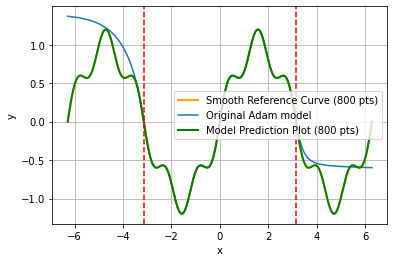

In [56]:
# Writing the periodic inputs for the model, evaluation and tests

Phi40 = torch.cat((torch.sin(X40),torch.cos(X40)),dim=0)

Phi_test = torch.cat((torch.sin(Xtest), torch.cos(Xtest)), dim=0)

# Model run with the new periodic feature

params_adam_periodic, losses_adam_perioic = train_model_adam(Phi40, Y40)

with torch.no_grad():
    Ypred_period = forward_pass(*params_adam_periodic, Phi_test)
    Ypred_original = forward_pass(*params_adam, Xtest)

# Plots the true reference curve
plt.plot(xtest[0], ytrue[0], color='orange', linestyle='-', linewidth=2, label='Smooth Reference Curve (800 pts)')

# Plots the original Adam model over the training set
plt.plot(Xtest[0], Ypred_original[0].numpy(),label="Original Adam model")

# Plots the models prediction over 800 points
plt.plot(Xtest[0].numpy(), Ypred_period[0].numpy(), color ='green', linestyle = '-', linewidth=2, label='Model Prediction Plot (800 pts)')

plt.xlabel("x")
plt.ylabel("y")
plt.axvline(x=-np.pi, color='red', linestyle='--')
plt.axvline(x=np.pi, color='red', linestyle='--')
plt.legend()
plt.grid(True)
plt.show()

In [61]:
## Calculating the MSE for both models inside and outside training domain

# Select points inside and outside the training interval
inside = np.abs(xtest[0]) <= np.pi
outside = ~inside

# Residuals: prediction minus true value
raw_residual = Ypred_original[0].numpy() - ytrue[0]
periodic_residual = Ypred_period[0].numpy() - ytrue[0]

# Average squared errors within each region
raw_inside_mse = np.mean(raw_residual[inside]**2)
raw_outside_mse = np.mean(raw_residual[outside]**2)

periodic_inside_mse = np.mean(periodic_residual[inside]**2)
periodic_outside_mse = np.mean(periodic_residual[outside]**2)

print("Raw model — inside:", raw_inside_mse)
print("Raw model — outside:", raw_outside_mse)
print("Periodic model — inside:", periodic_inside_mse)
print("Periodic model — outside:", periodic_outside_mse)

Raw model — inside: 1.7620502456060832e-05
Raw model — outside: 0.19022195405410153
Periodic model — inside: 1.9696043948989233e-06
Periodic model — outside: 1.969730318462413e-06


The above results clearly indicate that our periodic model is successful in accurately fitting the desired function. With this we have finished our second project, the function fitting model. We explored many different avenues; data quantity, learning rate, width, optimisation and how changing the mathematical structure of the inputs results in varied outputs. 

There are many takeaways from this project as discussed throughout the notebook. However, we must make an important comment about the results. Whilst it may appear that the model predicts the functions periodicity very strongly, this is purely because we have designed it to be so. Namely, we have forced the inputs to be periodic in $2\pi$ and therefore the output too. Specifically, no matter where we were up to in our training, the model would output a periodic function in $2\pi$. This highlights that we still have a lot to learn. The model didn't pick up the periodicity on it's own, nor did it encode it in without us forcing it. This is something that we will need to explore in the future. 

I finish with the important question of; how can we design a model that is able to recognise and encapsulate the periodicity of a function or greater problem without writing it into the model? 